# PROJECT: PREDICTING THE SEX OF LAYSAN ALBATROSS

In [4]:
# 1. IMPORT LIBRARIES

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [6]:
# 2. LOAD DATA
# ============================================================

# Extract ZIP file
zip_path = "predicting-the-sex-of-laysan-albatross.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("albatross_data")

# Load CSV files
train = pd.read_csv("albatross_data/train.csv")
test = pd.read_csv("albatross_data/test.csv")
sample_submission = pd.read_csv(
    "albatross_data/sample_submission.csv"
)

print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Training data shape: (94, 14)
Testing data shape: (41, 13)
Sample submission shape: (3, 2)


In [7]:
# 3. UNDERSTAND THE DATA
# ============================================================

print("\nFirst five records:")
print(train.head())

print("\nLast five records:")
print(train.tail())

print("\nColumn names:")
print(train.columns)

print("\nData information:")
train.info()

print("\nStatistical description:")
print(train.describe())

print("\nMissing values:")
print(train.isnull().sum())

print("\nDuplicate records:")
print(train.duplicated().sum())

print("\nTarget distribution:")
print(train["sexo"].value_counts())

print("\nUnique target values:")
print(train["sexo"].unique())

print("\nUnique IDs:")
print(train["id"].nunique())


First five records:
         id sexo  longitudCraneo  longitudPico  longitudNarina  anchoCraneo  \
0  0J4_2016    H          174.18        106.85           80.19        52.43   
1  A68_2016    H          171.12        104.59           79.45        51.14   
2  E55_2015    H          174.69        106.83           82.14        49.09   
3  7C7_2016    M          182.25        113.17           84.13        52.26   
4  2C0_2018    H          173.70        105.19           80.37        49.20   

   altoPico  anchoPico  tarso  longAlaCerrada  longAlaAbierta  \
0     30.20      23.26  88.74            51.0            95.7   
1     30.61      24.04  90.22            50.5            94.4   
2     30.60      26.47  91.42            52.7            96.6   
3     32.08      26.07  91.74            52.6            98.9   
4     34.00      27.12  87.77            50.8            94.5   

   mediaEnvergadura  envergadura  peso  
0             104.2        208.4  2.38  
1             102.2        204.

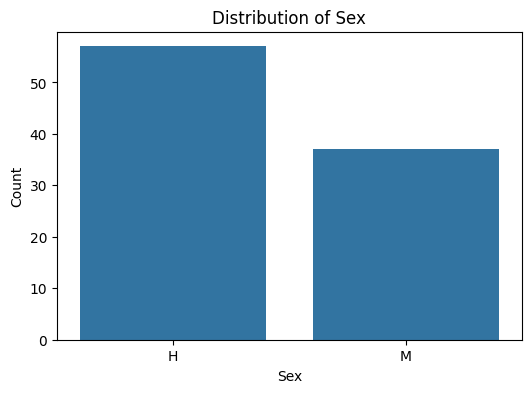

In [8]:
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Target distribution

plt.figure(figsize=(6, 4))
sns.countplot(data=train, x="sexo")
plt.title("Distribution of Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

In [9]:
# Target percentage

print("\nTarget percentage:")
print(train["sexo"].value_counts(normalize=True) * 100)


Target percentage:
sexo
H    60.638298
M    39.361702
Name: proportion, dtype: float64


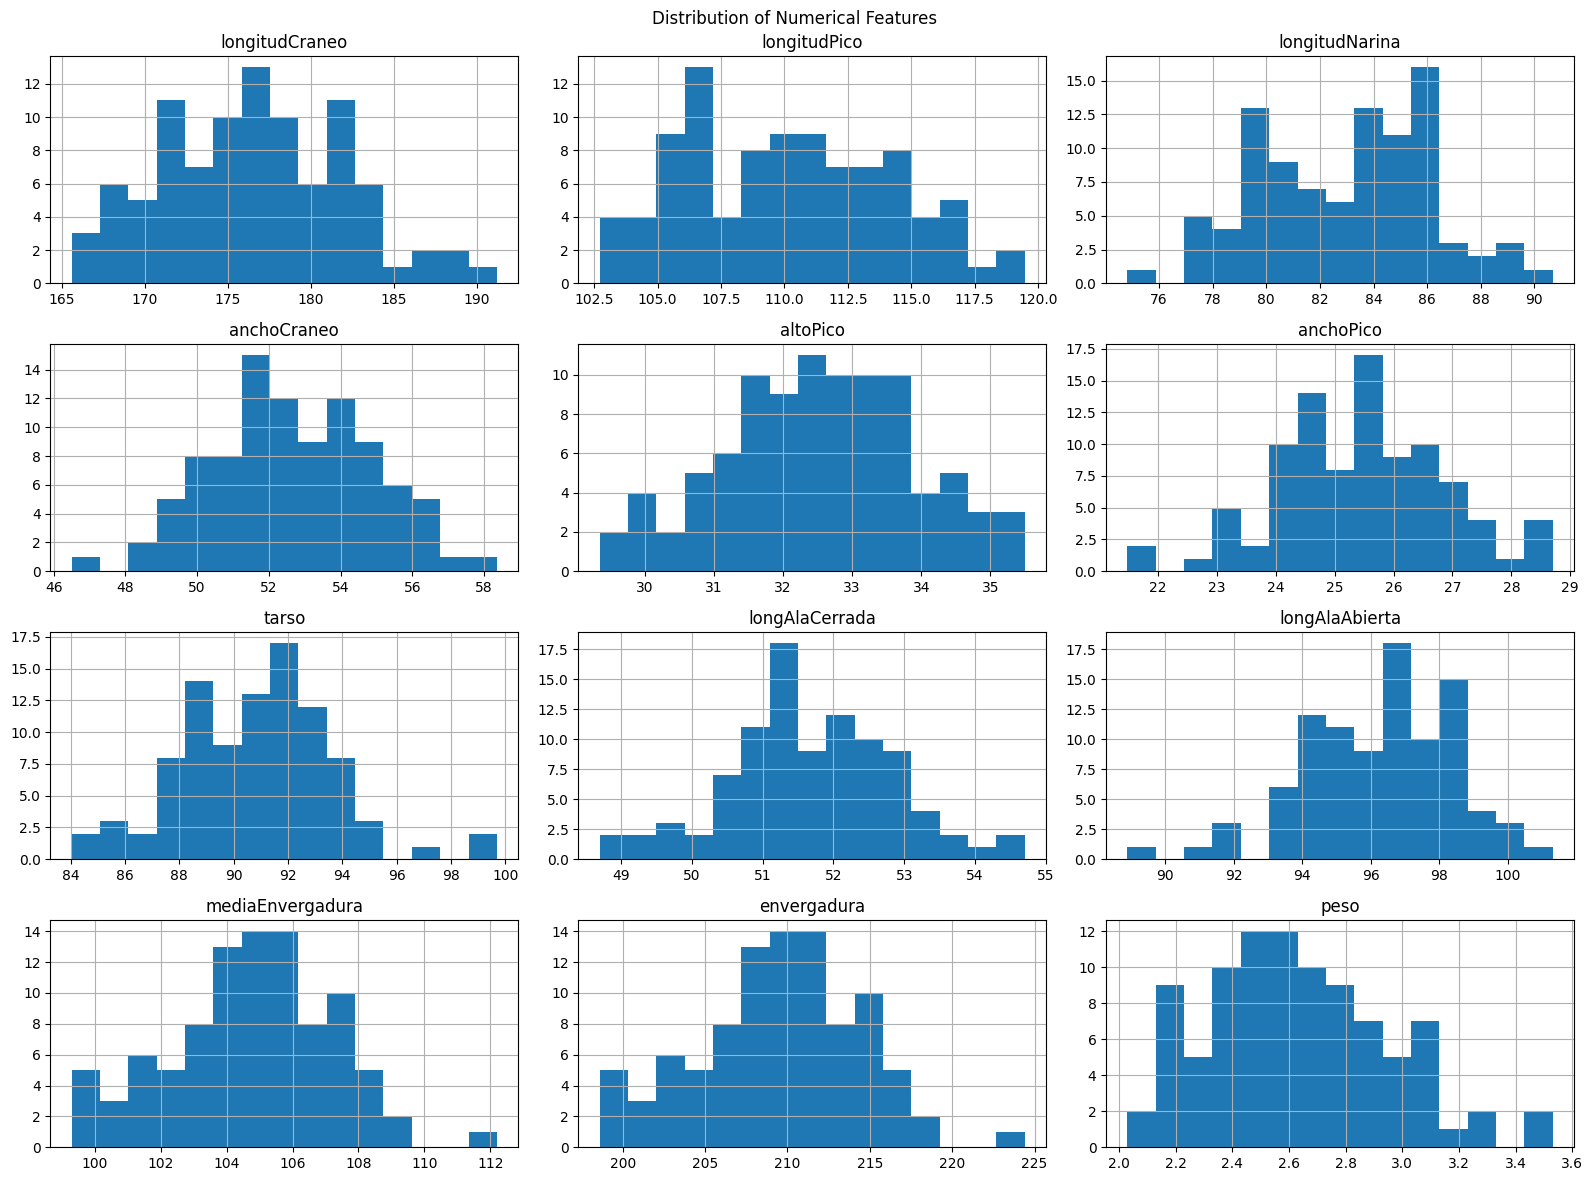

In [12]:
# Numerical feature distributions

train.hist(figsize=(16, 12), bins=15)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

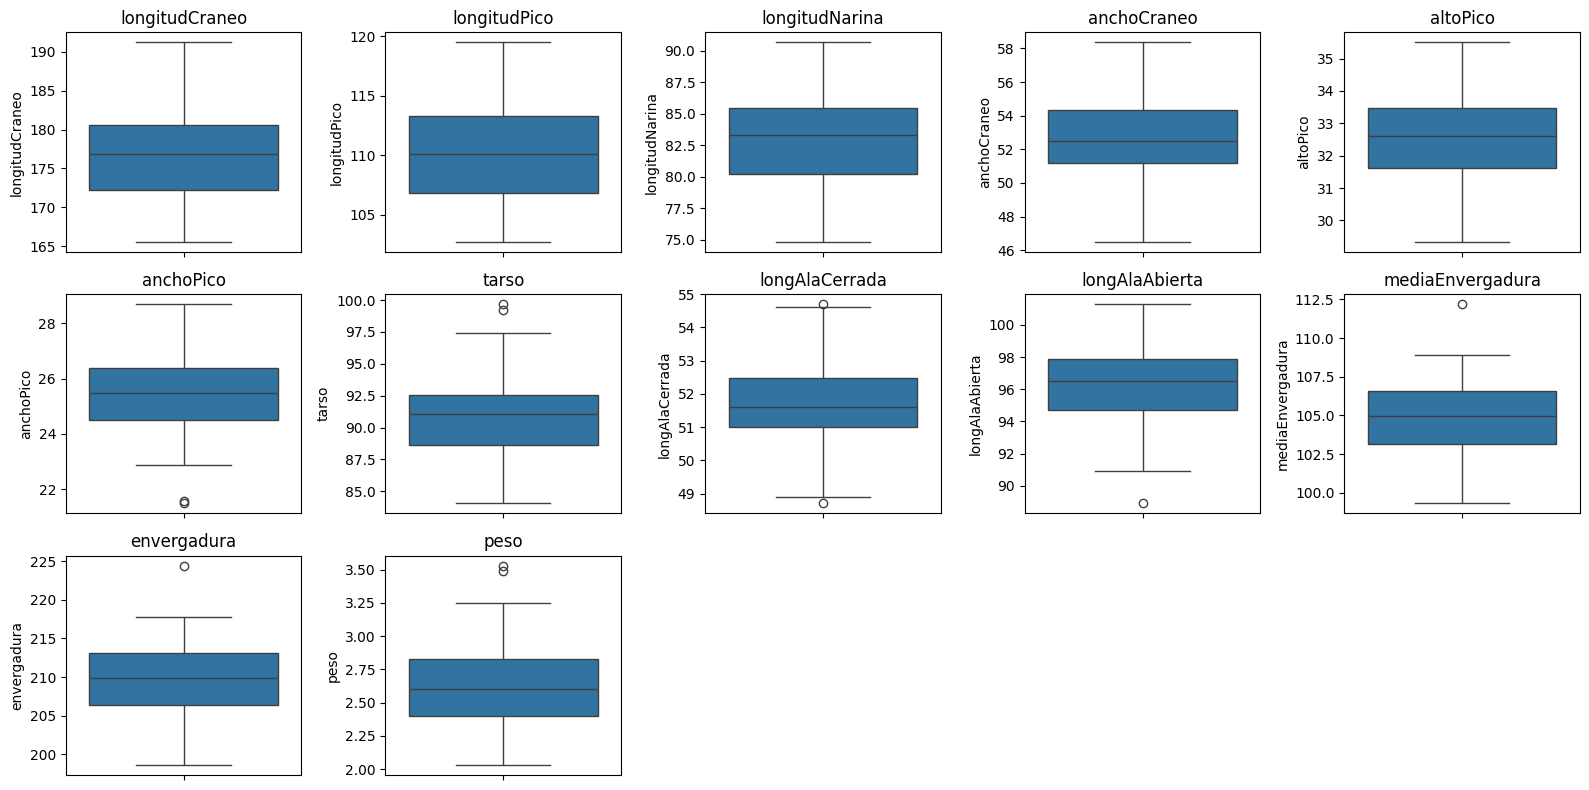

In [13]:
# Boxplots for detecting outliers

numeric_columns = train.select_dtypes(
    include=np.number
).columns

plt.figure(figsize=(16, 8))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(3, 5, i)
    sns.boxplot(y=train[col])
    plt.title(col)

plt.tight_layout()
plt.show()

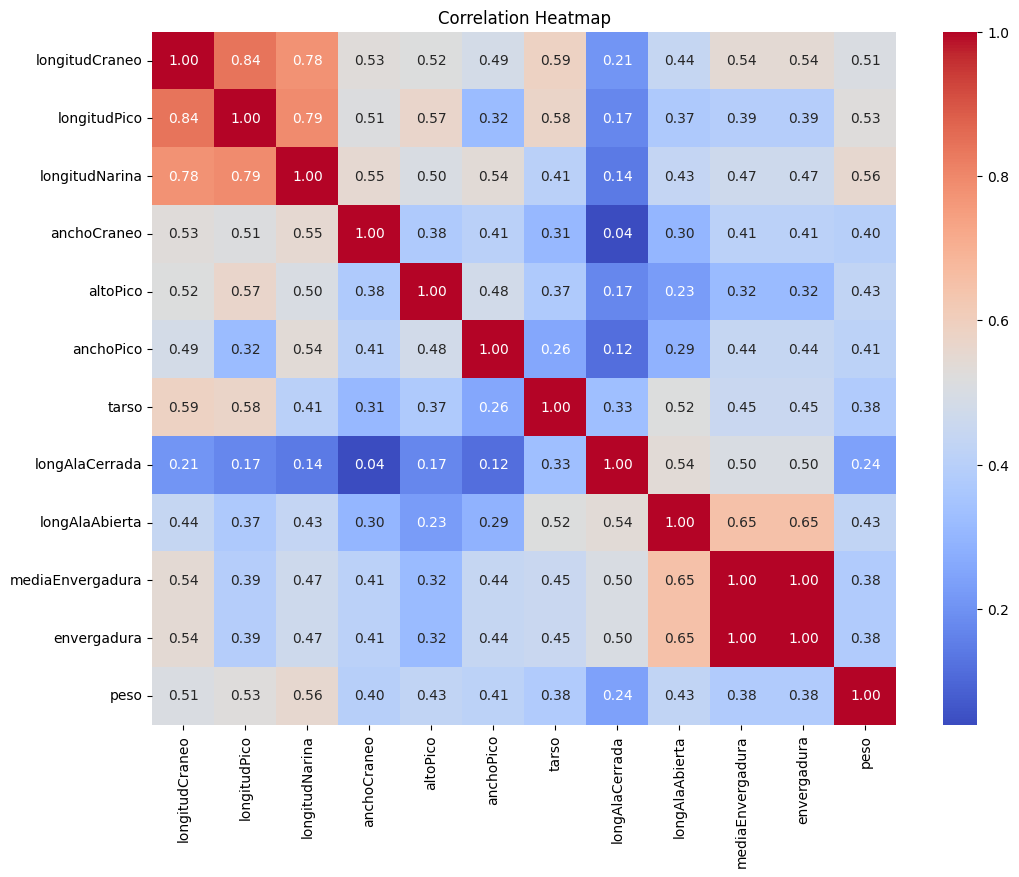

In [14]:
# Correlation heatmap

plt.figure(figsize=(12, 9))

correlation = train[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


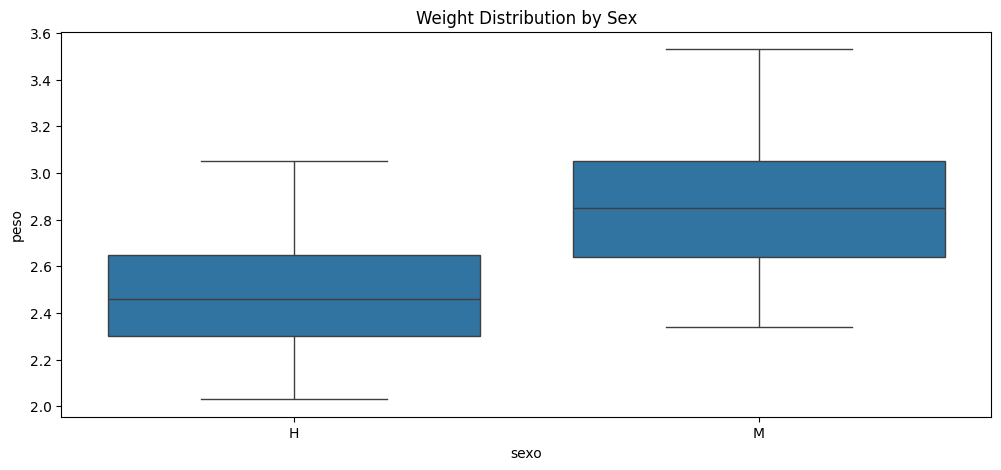

In [15]:
# Compare feature distributions by target

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=train,
    x="sexo",
    y="peso"
)

plt.title("Weight Distribution by Sex")
plt.show()


In [16]:
# 5. DATA PREPROCESSING
# ============================================================

# Remove ID from model features.
# ID is only required for final submission.

X = train.drop(columns=["id", "sexo"])

# Target variable

y = train["sexo"]

In [17]:
# Test features

X_test = test.drop(columns=["id"])

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)


Input features:
['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']

Target variable:
sexo


In [18]:
# Check feature consistency

assert list(X.columns) == list(X_test.columns)

print("\nTraining and testing features match.")


Training and testing features match.


In [19]:
# 6. TRAIN-VALIDATION SPLIT
# ============================================================

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining feature shape:", X_train.shape)
print("Validation feature shape:", X_valid.shape)

print("\nTraining target shape:", y_train.shape)
print("Validation target shape:", y_valid.shape)


Training feature shape: (70, 12)
Validation feature shape: (24, 12)

Training target shape: (70,)
Validation target shape: (24,)


In [20]:
# 7. BUILD MACHINE LEARNING MODELS
# ============================================================

models = {

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced"
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ])

}

In [21]:
# 8. MODEL TRAINING AND COMPARISON
# ============================================================

results = []

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict validation data
    pred = model.predict(X_valid)

    # Evaluation metrics
    accuracy = accuracy_score(y_valid, pred)

    precision = precision_score(
        y_valid, pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_valid, pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_valid, pred,
        average="macro",
        zero_division=0
    )

    # Cross-validation
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "CV F1": cv_scores.mean()
    })


In [22]:
# Convert results into DataFrame

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\nMODEL COMPARISON:")
print(results_df)


MODEL COMPARISON:
                 Model  Accuracy  Precision    Recall  F1 Score     CV F1
0  Logistic Regression  0.875000   0.875000  0.855556  0.863378  0.911224
3          Extra Trees  0.875000   0.875000  0.855556  0.863378  0.911239
1                  SVM  0.833333   0.840336  0.800000  0.812500  0.881394
2        Random Forest  0.833333   0.840336  0.800000  0.812500  0.877518


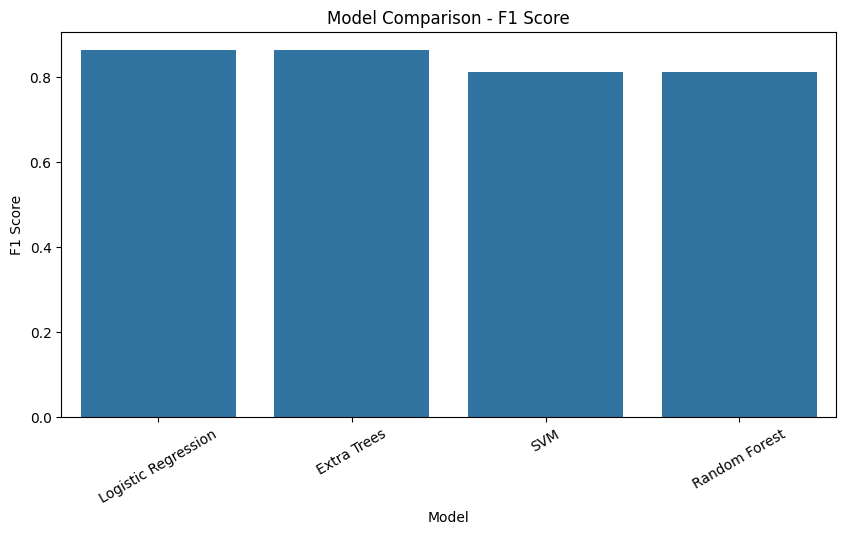

In [23]:
# Visualize model comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Model Comparison - F1 Score")
plt.xticks(rotation=30)
plt.show()

In [27]:
# 9. HYPERPARAMETER TUNING USING SVM
# ============================================================

# Use the SVM model

svm_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("model", SVC(
        class_weight="balanced"
    ))

])


# Hyperparameter combinations

param_grid = {

    "model__C": [0.1, 1, 10, 100],

    "model__kernel": ["linear", "rbf"],

    "model__gamma": ["scale", "auto"]

}


# GridSearchCV

grid_search = GridSearchCV(

    estimator=svm_pipeline,

    param_grid=param_grid,

    cv=cv,

    scoring="f1_macro",

    n_jobs=-1,

    verbose=1

)


# Train GridSearchCV

grid_search.fit(X_train, y_train)


# Best parameters

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1:")
print(grid_search.best_score_)


# Best model

best_model = grid_search.best_estimator_

Fitting 4 folds for each of 16 candidates, totalling 64 fits

Best Parameters:
{'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Best Cross Validation F1:
0.9114635547201337



Accuracy: 0.9166666666666666
Precision: 0.9111111111111111
Recall: 0.9111111111111111
F1 Score: 0.9111111111111111

Classification Report:
              precision    recall  f1-score   support

           H       0.93      0.93      0.93        15
           M       0.89      0.89      0.89         9

    accuracy                           0.92        24
   macro avg       0.91      0.91      0.91        24
weighted avg       0.92      0.92      0.92        24


Confusion Matrix:
[[14  1]
 [ 1  8]]


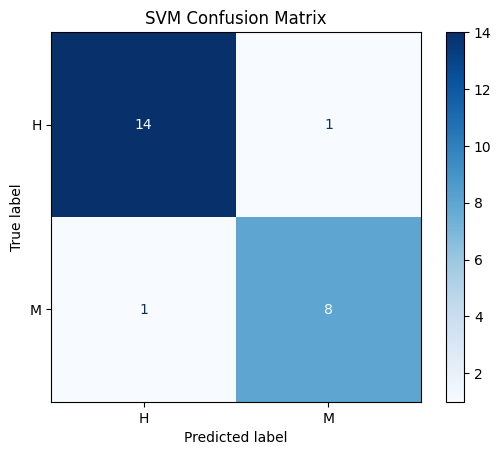

In [28]:
# 10. EVALUATE THE BEST MODEL
# ============================================================

# Validation prediction

y_pred = best_model.predict(X_valid)


# Accuracy

accuracy = accuracy_score(y_valid, y_pred)

print("\nAccuracy:", accuracy)


# Precision

precision = precision_score(
    y_valid,
    y_pred,
    average="macro",
    zero_division=0
)

print("Precision:", precision)


# Recall

recall = recall_score(
    y_valid,
    y_pred,
    average="macro",
    zero_division=0
)

print("Recall:", recall)


# F1 Score

f1 = f1_score(
    y_valid,
    y_pred,
    average="macro",
    zero_division=0
)

print("F1 Score:", f1)


# Classification report

print("\nClassification Report:")

print(
    classification_report(
        y_valid,
        y_pred,
        labels=["H", "M"],
        zero_division=0
    )
)


# Confusion Matrix

cm = confusion_matrix(
    y_valid,
    y_pred,
    labels=["H", "M"]
)

print("\nConfusion Matrix:")
print(cm)


# Confusion Matrix Visualization

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["H", "M"]
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.show()

In [29]:
# 11. FINAL MODEL TRAINING USING ALL TRAINING DATA
# ============================================================

# Hyperparameter tuning again using all labelled data

final_param_grid = {

    "model__C": [0.05, 0.1, 0.5, 1, 5, 10, 50, 100],

    "model__kernel": ["linear", "rbf"],

    "model__gamma": ["scale", "auto"]

}


final_grid = GridSearchCV(

    estimator=svm_pipeline,

    param_grid=final_param_grid,

    cv=cv,

    scoring="f1_macro",

    n_jobs=-1,

    verbose=1

)


# Train using all labelled training records

final_grid.fit(X, y)


# Final best model

final_model = final_grid.best_estimator_


print("\nFinal Best Parameters:")
print(final_grid.best_params_)

print("\nFinal Cross Validation F1:")
print(final_grid.best_score_)

Fitting 4 folds for each of 32 candidates, totalling 128 fits

Final Best Parameters:
{'model__C': 0.5, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Final Cross Validation F1:
0.8884707288745401


In [30]:
# 12. TEST DATA PREPROCESSING
# ============================================================

# Check test feature columns

print("\nTest feature shape:")
print(X_test.shape)

print("\nMissing values in test data:")
print(X_test.isnull().sum())

# The fitted pipeline automatically applies:
# 1. Median imputation
# 2. Standard scaling
#
# No separate fit is performed on test data.


Test feature shape:
(41, 12)

Missing values in test data:
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64


In [31]:
# 13. GENERATE TEST PREDICTIONS
# ============================================================

test_predictions = final_model.predict(X_test)

print("\nTest Predictions:")
print(test_predictions)

print("\nPrediction Distribution:")
print(pd.Series(test_predictions).value_counts())


Test Predictions:
['M' 'H' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'H' 'H' 'H' 'M' 'H' 'H' 'H' 'H'
 'H' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'H' 'H'
 'H' 'H' 'M' 'M' 'M']

Prediction Distribution:
M    22
H    19
Name: count, dtype: int64


In [32]:
# 14. PREPARE FINAL SUBMISSION FILE
# ============================================================

submission = pd.DataFrame({

    "id": test["id"],

    "sexo": test_predictions

})


# Check submission format against sample submission

print("\nSample Submission:")
print(sample_submission.head())

print("\nOur Submission:")
print(submission.head())


# Match the exact column order in sample submission

submission = submission[
    sample_submission.columns
]


Sample Submission:
     id sexo
0  id_1    M
1  id_2    H
2  id_3    M

Our Submission:
         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M


In [33]:
# 15. FINAL SUBMISSION VALIDATION
# ============================================================

# Check number of records

assert len(submission) == len(test) == 41


# Check column names

assert list(submission.columns) == ["id", "sexo"]


# Check IDs

assert submission["id"].equals(test["id"])


# Check missing values

assert submission.isnull().sum().sum() == 0


# Check predicted labels

assert set(submission["sexo"].unique()).issubset(
    set(y.unique())
)


# Check duplicate IDs

assert submission["id"].is_unique

In [34]:
# 16. SAVE SUBMISSION CSV
# ============================================================

submission.to_csv(
    "submission.csv",
    index=False
)


print("\n================================")
print("SUBMISSION FILE CREATED")
print("================================")

print(submission.head())

print("\nTotal Predictions:", len(submission))

print("\nPrediction Counts:")
print(submission["sexo"].value_counts())

print("\nMissing Values:")
print(submission.isnull().sum())

print("\nFile saved successfully as submission.csv")


SUBMISSION FILE CREATED
         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M

Total Predictions: 41

Prediction Counts:
sexo
M    22
H    19
Name: count, dtype: int64

Missing Values:
id      0
sexo    0
dtype: int64

File saved successfully as submission.csv


In [35]:
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
# Read test file

# Check total records
print("Test records:", len(test))
print("Submission records:", len(submission))

# Check whether IDs match
print("IDs match:",
      test["id"].reset_index(drop=True).equals(
          submission["id"].reset_index(drop=True)
      ))

# Check duplicate IDs
print("Duplicate IDs:", submission["id"].duplicated().sum())

# Check missing values
print(submission.isnull().sum())

# Display submission
print(submission.head())

Test records: 41
Submission records: 41
IDs match: True
Duplicate IDs: 0
id      0
sexo    0
dtype: int64
         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M


In [38]:
from google.colab import files

files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>